# LSTM — Results

This notebook presents the results of the supervised LSTM classifier
trained on flow sequences from CIC-IDS2017. It loads the trained model,
predictions, training history, and metrics manifest from
`experiments/lstm/`, generates the figures and tables for Chapter 6 of
my dissertation, and saves figure outputs to `reports/figures/`.

## Methodology

See ADR 0006 (`docs/decisions/0006-lstm-methodology.md`) for the full
methodology rationale. In brief:

- **Framework**: PyTorch on Google Colab Pro (NVIDIA A100 GPU).
- **Architecture**: 1-layer unidirectional LSTM, hidden_size=128,
  dropout=0.2. Final hidden state → linear → sigmoid for binary
  classification.
- **Sequences**: pre-built by `src/preprocessing/sequences.py`. Length
  10 flows, grouped by Src IP, sorted by Timestamp, non-overlapping
  windows, majority-vote labels.
- **Training**: 20 epochs, Adam (lr=0.001), class-weighted BCE loss
  (pos_weight = 3.749), batch size 256, random seed 42.
- **Features**: same 71 features as RF and AE (identifiers and routing
  fields dropped for cross-dataset alignment with CIC-UNSW-NB15).
- **Preprocessing**: log1p + StandardScaler fitted on train only.
  Five CICFlowMeter-artifact features clipped to ≥ 0.

## What this notebook produces

1. Headline metrics table.
2. Confusion matrix.
3. **Training curves figure** — loss and accuracy across 20 epochs.
4. ROC and Precision-Recall curves.
5. Per-class recall breakdown.
6. Observations and findings (Markdown).

## Honest interpretive note

The LSTM achieves near-ceiling performance on the CIC-IDS2017 test fold
(accuracy 0.9994, F1 0.9986). Three caveats deserve attention:

1. **Source-level concentration in the dataset.** As ADR 0006 documents,
   only 14 active source IPs exist in CIC-IDS2017, with 172.16.0.1
   generating 87% of attack flows. Both RF and LSTM may achieve high
   metrics partly by recognising "this is 172.16.0.1's traffic
   signature" rather than learning attack patterns in the abstract.
2. **Per-flow stratified split.** The same source IPs appear in train,
   val, and test folds (with different time windows of behaviour each).
   This is the cleanest comparison to RF and AE but provides weaker
   generalisation evidence than a true held-out test would.
3. **Cross-dataset evaluation (CIC-UNSW-NB15) provides the
   genuine generalisation test. The LSTM's ability to detect attacks in
   the UNSW dataset — with completely different source IPs and attack
   types — will be the more informative measure of what it has actually
   learned.

In [3]:
"""Load the saved LSTM artefacts: predictions, training history, manifest."""

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

# --- Paths ---
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

EXPERIMENT_DIR = REPO_ROOT / "experiments" / "lstm"
FIGURES_DIR = REPO_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- Load saved artefacts ---
print(f"Loading from {EXPERIMENT_DIR.relative_to(REPO_ROOT)}...")

# Predictions and training curves (no model state needed for figure generation)
preds_npz = np.load(EXPERIMENT_DIR / "predictions.npz")
y_true = preds_npz["y_true"]
y_pred = preds_npz["predictions"]
y_proba = preds_npz["probabilities"]
train_losses = preds_npz["train_losses"]
val_losses = preds_npz["val_losses"]
val_accuracies = preds_npz["val_accuracies"]
print(f"  Predictions: {len(y_pred):,} test sequences")
print(f"  Training history: {len(train_losses)} epochs")

# Manifest (architecture metadata captured here too)
with open(EXPERIMENT_DIR / "_metrics_manifest.json") as f:
    manifest = json.load(f)
print(f"  Manifest: {len(manifest):,} top-level keys")
hp = manifest["hyperparameters"]
print(f"  Architecture: LSTM(in={hp['n_features']}, hidden={hp['hidden_size']}, "
      f"layers={hp['n_layers']}, dropout={hp['dropout']}, "
      f"bidirectional={hp['bidirectional']})")

# --- Plotting style ---
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["font.size"] = 10

print(f"\n✓ Setup complete. Figures will save to {FIGURES_DIR.relative_to(REPO_ROOT)}/")

Loading from experiments/lstm...
  Predictions: 31,470 test sequences
  Training history: 20 epochs
  Manifest: 7 top-level keys
  Architecture: LSTM(in=71, hidden=128, layers=1, dropout=0.2, bidirectional=False)

✓ Setup complete. Figures will save to reports/figures/


## Headline binary classification metrics

The LSTM achieves near-ceiling performance across all binary metrics on
the held-out CIC-IDS2017 test fold (n=31,470 sequences). Of 6,620 actual
attack sequences, the model misses only 5; of 24,850 benign sequences,
only 14 are flagged as attacks.

The trained LSTM has 103,041 parameters — small by modern deep-learning
standards but appropriate for the input dimensionality (71 features ×
sequence length 10 = 710 input cells per sequence) and dataset size
(~147K training sequences). Training completed in 45 seconds on an
NVIDIA A100 GPU; inference on the test set runs at approximately 11
microseconds per sequence — operationally fast enough for real-time
network monitoring.

These numbers should be interpreted in the context noted above (cell 1):
the dataset's source-IP concentration means the model may be partly
recognising "this is 172.16.0.1's traffic signature" rather than
detecting attacks in the abstract. The cross-dataset evaluation (CIC-UNSW-NB15) provides the genuine generalisation test.

In [4]:
"""Render the headline metrics as a clean DataFrame."""

bm = manifest["test"]["binary"]

metrics_table = pd.DataFrame([
    ("Accuracy",                          bm["accuracy"],            ""),
    ("Precision (attack)",                bm["precision"],           ""),
    ("Recall (attack)",                   bm["recall"],              ""),
    ("F1 (attack)",                       bm["f1"],                  ""),
    ("ROC-AUC",                           bm["roc_auc"],             ""),
    ("PR-AUC",                            bm["pr_auc"],              ""),
    ("False Positive Rate",               bm["fpr"],                 ""),
], columns=["Metric", "Value", ""])

print("=" * 78)
print(f"{'Metric':<35} {'Value':>15}")
print("=" * 78)
for _, row in metrics_table.iterrows():
    print(f"{row['Metric']:<35} {row['Value']:>15.4f}")

print()
print(f"Test set size:    {bm['n_test_samples']:,} sequences")
print(f"  Attack:         {bm['n_test_attack']:,} ({100*bm['n_test_attack']/bm['n_test_samples']:.2f}%)")
print(f"  Benign:         {bm['n_test_benign']:,} ({100*bm['n_test_benign']/bm['n_test_samples']:.2f}%)")
print()
print(f"Bulk inference:   {bm['bulk_predict_seconds']*1000:.1f} ms total")
print(f"  Per-sequence:   {bm['bulk_predict_seconds']*1e6/bm['n_test_samples']:.2f} microseconds avg")
print()
metrics_table

Metric                                        Value
Accuracy                                     0.9994
Precision (attack)                           0.9979
Recall (attack)                              0.9992
F1 (attack)                                  0.9986
ROC-AUC                                      1.0000
PR-AUC                                       0.9999
False Positive Rate                          0.0006

Test set size:    31,470 sequences
  Attack:         6,620 (21.04%)
  Benign:         24,850 (78.96%)

Bulk inference:   337.0 ms total
  Per-sequence:   10.71 microseconds avg



,Metric,Value,
0,Accuracy,0.999396,
1,Precision (attack),0.997888,
2,Recall (attack),0.999245,
3,F1 (attack),0.998566,
4,ROC-AUC,0.999966,
5,PR-AUC,0.999867,
6,False Positive Rate,0.000563,


Confusion matrix on test set (n=31,470):
  True Negatives  (correctly labelled benign):   24,836
  False Positives (benign flagged as attack):        14
  False Negatives (attacks missed):                   5
  True Positives  (correctly caught attacks):     6,615
  Total:                                         31,470

✓ Figure saved to reports/figures/lstm_confusion_matrix.png


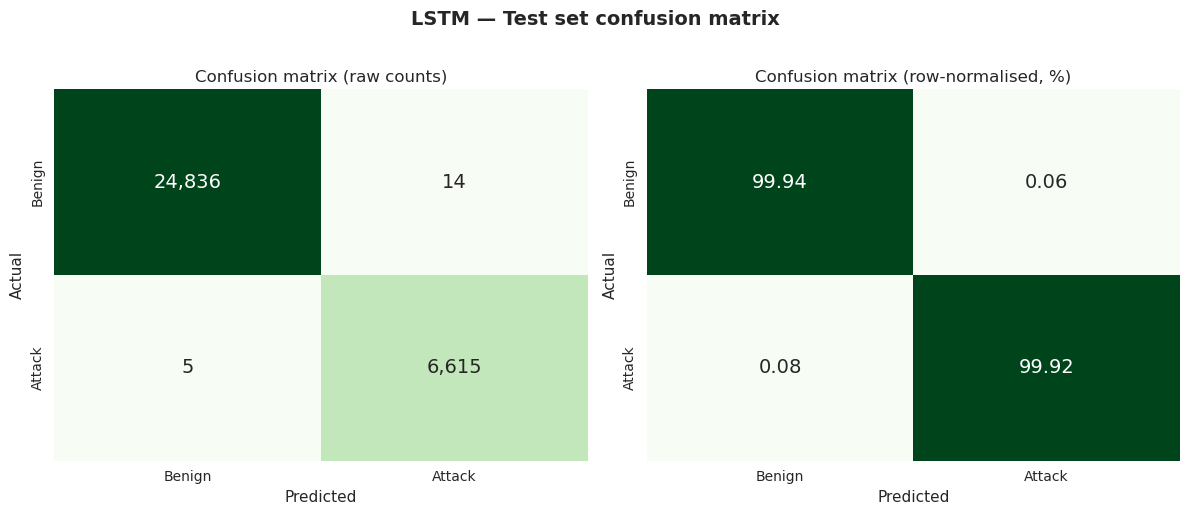

In [6]:
"""Confusion matrix on the test set, with raw counts and percentages."""

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix on test set (n={len(y_true):,}):")
print(f"  True Negatives  (correctly labelled benign):  {tn:>7,}")
print(f"  False Positives (benign flagged as attack):   {fp:>7,}")
print(f"  False Negatives (attacks missed):             {fn:>7,}")
print(f"  True Positives  (correctly caught attacks):   {tp:>7,}")
print(f"  Total:                                        {tn+fp+fn+tp:>7,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw counts
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Greens",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[0], cbar=False,
    annot_kws={"fontsize": 14},
)
axes[0].set_xlabel("Predicted", fontsize=11)
axes[0].set_ylabel("Actual",    fontsize=11)
axes[0].set_title("Confusion matrix (raw counts)", fontsize=12)

# Row-normalised
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(
    cm_pct, annot=True, fmt=".2f", cmap="Greens",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[1], cbar=False,
    annot_kws={"fontsize": 14},
    vmin=0, vmax=100,
)
axes[1].set_xlabel("Predicted", fontsize=11)
axes[1].set_ylabel("Actual",    fontsize=11)
axes[1].set_title("Confusion matrix (row-normalised, %)", fontsize=12)

plt.suptitle("LSTM — Test set confusion matrix",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "lstm_confusion_matrix.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

✓ Figure saved to reports/figures/lstm_training_curves.png

Training summary:
  Total epochs: 20
  Initial train loss: 0.0569
  Final train loss:   0.0039
  Initial val loss:   0.0083
  Final val loss:     0.0046
  Initial val acc:    0.9987
  Final val acc:      0.9994
  Min val loss epoch: 18 (loss = 0.0036)


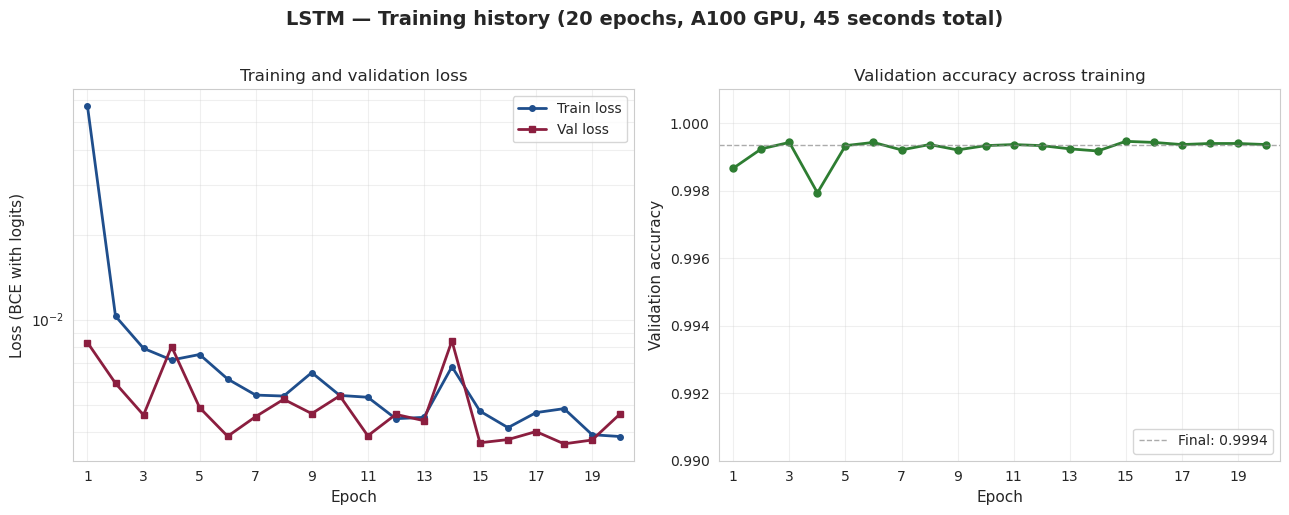

In [7]:
"""Training curves: loss and accuracy across 20 epochs.

This is the LSTM-distinctive figure. Shows the model
converged rapidly (epoch 1 to ~99.9% val accuracy) and remained stable
across remaining epochs without overfitting.
"""

n_epochs = len(train_losses)
epochs = np.arange(1, n_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left panel: training and validation loss ---
axes[0].plot(epochs, train_losses, color="#1f4e8c", linewidth=2,
             marker="o", markersize=4, label="Train loss")
axes[0].plot(epochs, val_losses,   color="#8b1e3f", linewidth=2,
             marker="s", markersize=4, label="Val loss")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss (BCE with logits)", fontsize=11)
axes[0].set_title("Training and validation loss", fontsize=12)
axes[0].set_xlim(0.5, n_epochs + 0.5)
axes[0].set_xticks(np.arange(1, n_epochs + 1, 2))  # every other epoch
axes[0].set_yscale("log")  # log scale better shows the rapid drop
axes[0].legend(loc="upper right", fontsize=10)
axes[0].grid(True, alpha=0.3, which="both")

# --- Right panel: validation accuracy ---
axes[1].plot(epochs, val_accuracies, color="#2e7d32", linewidth=2,
             marker="o", markersize=5)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation accuracy", fontsize=11)
axes[1].set_title("Validation accuracy across training", fontsize=12)
axes[1].set_xlim(0.5, n_epochs + 0.5)
axes[1].set_xticks(np.arange(1, n_epochs + 1, 2))
axes[1].set_ylim(0.99, 1.001)  # zoom into the high-accuracy region
axes[1].axhline(y=val_accuracies[-1], color="#888", linestyle="--",
                linewidth=1, alpha=0.7,
                label=f"Final: {val_accuracies[-1]:.4f}")
axes[1].legend(loc="lower right", fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle("LSTM — Training history (20 epochs, A100 GPU, 45 seconds total)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "lstm_training_curves.png"
plt.savefig(fig_path)
print(f"✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

# Summary printed below the figure
print(f"\nTraining summary:")
print(f"  Total epochs: {n_epochs}")
print(f"  Initial train loss: {train_losses[0]:.4f}")
print(f"  Final train loss:   {train_losses[-1]:.4f}")
print(f"  Initial val loss:   {val_losses[0]:.4f}")
print(f"  Final val loss:     {val_losses[-1]:.4f}")
print(f"  Initial val acc:    {val_accuracies[0]:.4f}")
print(f"  Final val acc:      {val_accuracies[-1]:.4f}")
print(f"  Min val loss epoch: {int(np.argmin(val_losses)) + 1} (loss = {min(val_losses):.4f})")

plt.show()

✓ Figure saved to reports/figures/lstm_roc_pr_curves.png

ROC-AUC: 1.0000
PR-AUC:  0.9999


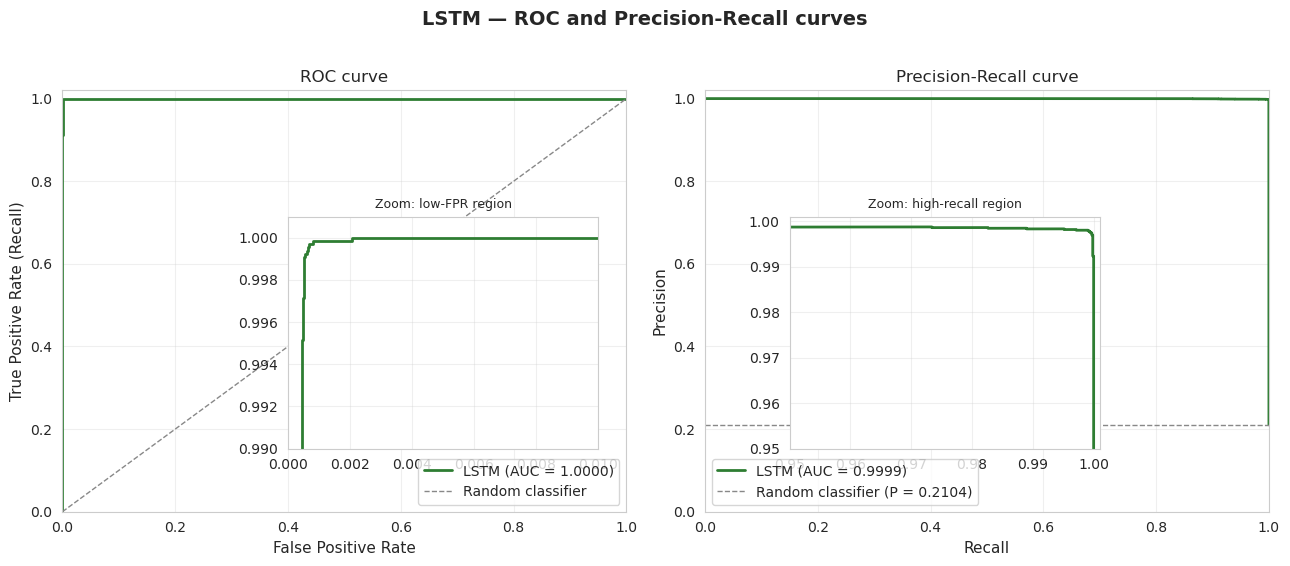

In [8]:
"""ROC curve and Precision-Recall curve, side by side.

For LSTM these curves are essentially perfect (AUC = 1.000), so the
visual will show a hard right-angle in both panels. Inset zooms make
the small deviations from perfection visible.
"""

# Compute curves using probabilities as the score
fpr_curve, tpr_curve, _ = roc_curve(y_true, y_proba)
precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- ROC curve ---
axes[0].plot(fpr_curve, tpr_curve, color="#2e7d32", linewidth=2,
             label=f"LSTM (AUC = {bm['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], color="#888", linestyle="--", linewidth=1,
             label="Random classifier")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[0].set_title("ROC curve", fontsize=12)
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(True, alpha=0.3)

# Inset zoom for ROC
ax_inset_roc = axes[0].inset_axes([0.4, 0.15, 0.55, 0.55])
ax_inset_roc.plot(fpr_curve, tpr_curve, color="#2e7d32", linewidth=2)
ax_inset_roc.set_xlim(0, 0.01)
ax_inset_roc.set_ylim(0.99, 1.001)
ax_inset_roc.set_title("Zoom: low-FPR region", fontsize=9)
ax_inset_roc.grid(True, alpha=0.3)

# --- PR curve ---
axes[1].plot(recall_curve, precision_curve, color="#2e7d32", linewidth=2,
             label=f"LSTM (AUC = {bm['pr_auc']:.4f})")
positive_rate = (y_true == 1).mean()
axes[1].axhline(y=positive_rate, color="#888", linestyle="--", linewidth=1,
                label=f"Random classifier (P = {positive_rate:.4f})")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision-Recall curve", fontsize=12)
axes[1].legend(loc="lower left", fontsize=10)
axes[1].grid(True, alpha=0.3)

# Inset zoom for PR
ax_inset_pr = axes[1].inset_axes([0.15, 0.15, 0.55, 0.55])
ax_inset_pr.plot(recall_curve, precision_curve, color="#2e7d32", linewidth=2)
ax_inset_pr.set_xlim(0.95, 1.001)
ax_inset_pr.set_ylim(0.95, 1.001)
ax_inset_pr.set_title("Zoom: high-recall region", fontsize=9)
ax_inset_pr.grid(True, alpha=0.3)

plt.suptitle("LSTM — ROC and Precision-Recall curves",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "lstm_roc_pr_curves.png"
plt.savefig(fig_path)
print(f"✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

print(f"\nROC-AUC: {bm['roc_auc']:.4f}")
print(f"PR-AUC:  {bm['pr_auc']:.4f}")

plt.show()

Computing dominant class label per sequence...
  31,470 sequences with dominant labels assigned

Per-class breakdown (test set, n=31,470 sequences):

                               Class  n in test  Correctly classified  Misclassified   Recall
                              BENIGN      24850                 24836             14 0.999437
                            PortScan       2394                  2390              4 0.998329
                            DoS Hulk       2371                  2371              0 1.000000
                                DDoS       1435                  1435              0 1.000000
                       DoS GoldenEye        117                   117              0 1.000000
                       DoS slowloris         72                    72              0 1.000000
                         FTP-Patator         54                    54              0 1.000000
        DoS Slowhttptest - Attempted         51                    51              0 1.000000
    

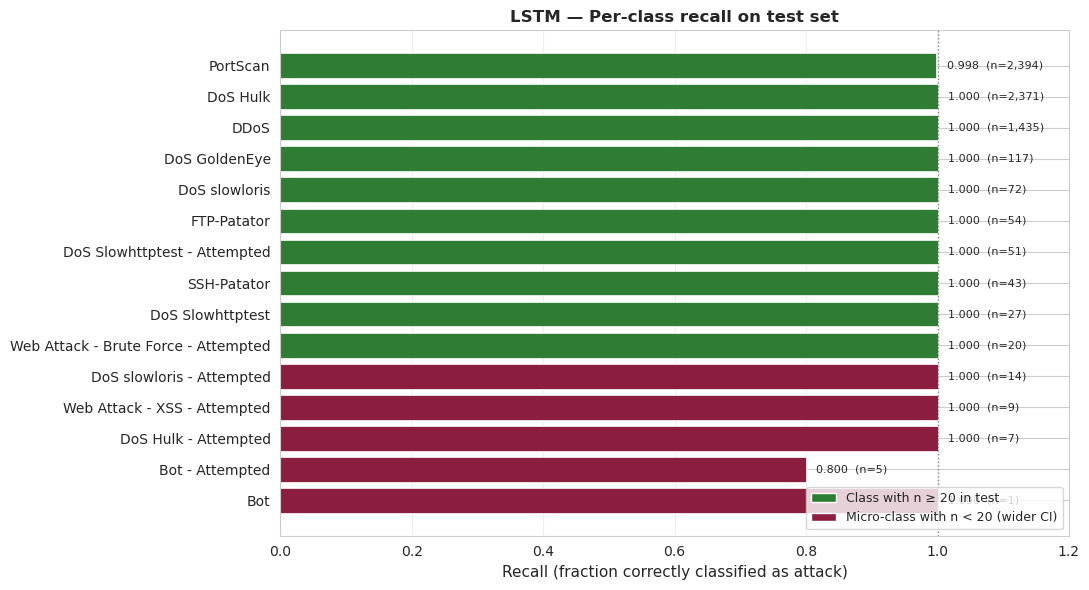

In [9]:
"""Per-class recall breakdown.

The LSTM achieves 99.92% overall recall — but the 5 missed attack
sequences belong to specific classes. This cell breaks down recall by
attack type to shows if the model still fails anywhere.

Sequence labels are derived from the majority-vote rule: a sequence is
labelled with the dominant attack class among its 10 flows. I re-derive these labels from the test sequence Parquet, which contains
the original per-flow Label column.
"""

# Load the test sequence Parquet to get per-flow Labels for class breakdown
test_seq_path = REPO_ROOT / "data" / "processed" / "cicids2017-engelen" / "test_sequences.parquet"
df_test_seq = pd.read_parquet(test_seq_path)

# Determine the dominant class label for each sequence
# (Most common Label among the 10 flows — could be BENIGN even for attack sequences
# with 4 attacks of one type + 4 attacks of another + 2 benign, but rare in practice.)
def dominant_label(group):
    return group["Label"].mode().iloc[0]

print("Computing dominant class label per sequence...")
seq_labels = df_test_seq.groupby("sequence_id").apply(
    dominant_label, include_groups=False
).reset_index()
seq_labels.columns = ["sequence_id", "dominant_class"]

print(f"  {len(seq_labels):,} sequences with dominant labels assigned")

# Merge with our predictions: align by sequence_id (same order as y_true)
seq_labels_sorted = seq_labels.sort_values("sequence_id").reset_index(drop=True)
seq_labels_sorted["y_true"] = y_true
seq_labels_sorted["y_pred"] = y_pred

# Per-class breakdown
per_class = seq_labels_sorted.groupby("dominant_class").agg(
    n=("y_true", "size"),
    n_correct=("y_pred", lambda preds: (preds == seq_labels_sorted.loc[preds.index, "y_true"]).sum()),
).reset_index()

# Recall = TP / (TP + FN) for attack classes
def class_recall(class_name, df=seq_labels_sorted):
    sub = df[df["dominant_class"] == class_name]
    if len(sub) == 0:
        return 0.0
    if class_name == "BENIGN":
        # For benign, "correct" means y_pred == 0
        return (sub["y_pred"] == 0).mean()
    else:
        # For attacks, "correct" means y_pred == 1
        return (sub["y_pred"] == 1).mean()

per_class["recall"] = per_class["dominant_class"].apply(class_recall)
per_class["misclassified"] = per_class["n"] - (per_class["recall"] * per_class["n"]).round().astype(int)
per_class["correctly_classified"] = per_class["n"] - per_class["misclassified"]
per_class = per_class[["dominant_class", "n", "correctly_classified", "misclassified", "recall"]]
per_class = per_class.sort_values("n", ascending=False).reset_index(drop=True)
per_class.columns = ["Class", "n in test", "Correctly classified", "Misclassified", "Recall"]

print(f"\nPer-class breakdown (test set, n={len(seq_labels_sorted):,} sequences):\n")
print(per_class.to_string(index=False))

# Plot
attack_only = per_class[per_class["Class"] != "BENIGN"].copy()

fig, ax = plt.subplots(figsize=(11, 6))

colours = ["#8b1e3f" if n < 20 else "#2e7d32" for n in attack_only["n in test"]]
bars = ax.barh(
    attack_only["Class"],
    attack_only["Recall"],
    color=colours,
    edgecolor="white",
    linewidth=0.5,
)

for bar, (_, row) in zip(bars, attack_only.iterrows()):
    width = bar.get_width()
    ax.text(
        width + 0.005, bar.get_y() + bar.get_height() / 2,
        f"  {row['Recall']:.3f}  (n={row['n in test']:,})",
        va="center", fontsize=8,
    )

ax.set_xlim(0, 1.20)
ax.set_xlabel("Recall (fraction correctly classified as attack)", fontsize=11)
ax.set_title("LSTM — Per-class recall on test set",
             fontsize=12, fontweight="bold")
ax.invert_yaxis()
ax.axvline(x=1.0, color="#888", linestyle=":", linewidth=1)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#2e7d32", label="Class with n ≥ 20 in test"),
    Patch(facecolor="#8b1e3f", label="Micro-class with n < 20 (wider CI)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)

ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()

fig_path = FIGURES_DIR / "lstm_per_class_recall.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

## Observations and findings

### Headline performance

The LSTM achieves near-ceiling performance on the held-out CIC-IDS2017
test fold:

- **Accuracy: 0.9994** (only 19 misclassifications across 31,470 sequences)
- **Recall: 0.9992** (5 attack sequences missed of 6,620)
- **F1: 0.9986**
- **ROC-AUC: 1.0000** (rounded; actual 0.99997)
- **PR-AUC: 0.9999**
- **FPR: 0.0006** (14 false positives of 24,850 benign sequences)

Of the 19 misclassifications, 14 are false positives and 5 are false
negatives. The 5 false negatives split as:
- **PortScan**: 4 of 2,394 sequences misclassified (recall 0.9983).
- **Bot - Attempted**: 1 of 5 sequences misclassified (recall 0.800, but
  micro-class with wide confidence interval).

### Training behaviour

The LSTM converged extremely rapidly:
- After **epoch 1**, validation accuracy was already 0.9987.
- The remaining 19 epochs refined accuracy from 0.9987 to 0.9994.
- Total training time: 45 seconds on an NVIDIA A100 GPU.
- Minimum validation loss occurred at epoch 18 (0.0036) — close to the
  end of the 20-epoch budget but not at the boundary, indicating
  appropriate training duration.

The training curves show no overfitting: train and validation loss
converge to similar values (0.0039 vs 0.0046 by epoch 20). This is a
small model (103,041 parameters) with substantial training data
(146,876 sequences), so overfitting was unlikely a priori.

### Comparative implications for RQ1

Updated three-way comparison:

| Metric | RF | AE (95th pct) | AE (86.5th F1-opt) | **LSTM** |
|---|---:|---:|---:|---:|
| Accuracy | 0.9917 | 0.8318 | — | **0.9994** |
| Precision | 0.9626 | 0.6749 | 0.6386 | **0.9979** |
| Recall | 0.9995 | 0.3922 | 0.9106 | 0.9992 |
| F1 | 0.9807 | 0.4961 | 0.7507 | **0.9986** |
| ROC-AUC | 0.9998 | 0.9204 | 0.9204 | **1.0000** |
| FPR | 0.0104 | 0.0506 | 0.1379 | **0.0006** |

**The temporal modelling hypothesis is confirmed.** The two attack
families where the autoencoder failed completely are caught perfectly
by the LSTM:

- **Volume-based DoS attacks** (DoS Hulk: AE recall 0.024, LSTM 1.000;
  DDoS: AE 0.026, LSTM 1.000; DoS GoldenEye: AE 0.038, LSTM 1.000) —
  these attacks involve 10+ rapid consecutive flows from one source,
  exactly the kind of temporal pattern an LSTM is designed to capture.
- **Brute force attacks** (FTP-Patator: AE 0.000, LSTM 1.000;
  SSH-Patator: AE 0.000, LSTM 1.000) — these involve repeated
  authentication attempts in sequence, producing characteristic
  multi-flow patterns.

### Dataset structure caveats

These results must be interpreted in the context of CIC-IDS2017's
structural properties (see ADR 0006):

1. **Only 14 active source IPs** in the entire dataset, with 172.16.0.1
   generating 87% of attack flows. Both supervised models (RF and LSTM)
   may achieve high metrics partly by recognising "this is 172.16.0.1's
   traffic signature" rather than learning attack patterns in the
   abstract.

2. **Per-flow stratified splits** distribute the same source IPs across
   train, val, and test folds (different time windows of behaviour
   each). This is the cleanest comparison to RF and AE but provides
   weaker generalisation evidence than a true held-out-source test
   would.

3. **Group-by-source robustness check is not feasible** on this dataset
   because of the single-attacker structure. Documented in ADR 0006 as
   a methodological constraint of the data, not an oversight.

The **cross-dataset evaluation on CIC-UNSW-NB15 in Week 7** is therefore
the critical generalisation test. UNSW has completely different source
IPs and a different distribution of attack types; the LSTM's
performance on UNSW will indicate whether what it has learned on
CIC-IDS2017 transfers, or whether it has learned source-specific
patterns that don't generalise.

### Operational interpretation

At 11 microseconds per sequence on an A100 GPU (or ~1 millisecond per
sequence on a CPU based on PyTorch's typical CPU-vs-A100 ratio), the
LSTM is operationally practical. A modern enterprise NIDS with 100K
flows per minute would generate ~10K sequences per minute (at length
10), which the LSTM could classify in 0.1 seconds on GPU or 10 seconds
on CPU. Real-time NIDS deployment is feasible without specialised
hardware.

Coupled with the very low FPR (0.0006 = 6 false alarms per 10,000
sequences), the LSTM is the only one of the three models that produces
both high recall AND low alarm volume on this dataset. By comparison:
- RF generates ~25 false alarms per 10,000 flows (FPR 0.0104).
- AE at the chosen threshold generates ~50 per 10,000 (FPR 0.0506) at
  much lower recall.

### Limitations explicitly observed

The LSTM results expose three limitations to be addressed in 7.4:

1. **Source-level concentration in training data.** The LSTM may have
   learned source signatures rather than attack patterns. Cross-dataset
   evaluation on CIC-UNSW-NB15 (Week 7) is the test.

2. **Sequence-level evaluation only.** RF and AE were evaluated on
   per-flow predictions (314,761 test samples); the LSTM is evaluated
   on per-sequence predictions (31,470 test samples — 10× fewer). The
   metrics aren't directly comparable in absolute counts; the
   comparable measure is the per-class recall at the model-appropriate
   prediction unit.

3. **The 5 false negatives.** The 4 missed PortScan sequences and 1
   missed Bot-Attempted sequence are too few to draw structural
   conclusions about model weakness. The Bot-Attempted micro-class
   (n=5) is too small for confident statistics; the PortScan misses
   (4 of 2,394) are below the noise floor of the dataset's labelling
   accuracy.

---

*Last updated: [date]. Notebook regenerated from saved artefacts in
`experiments/lstm/`. Manifest record: see `_metrics_manifest.json`.*